In [64]:
import pandas as pd
import numpy as np

Partie 1 : Data frame 

In [65]:
df = pd.DataFrame({
    "segment": ["Large Corporates", "SMEs", "Real estate", "Mortgages", "Consumer loans"],
    "type":    ["Entreprises", "Entreprises", "Entreprises", "Particuliers", "Particuliers"],
    "EAD":     [42, 28, 9, 31, 14],
    "PD":      [0.012, 0.035, 0.04, 0.015, 0.045],
    "LGD":     [0.40, 0.45, 0.40, 0.20, 0.65],
})
df

,segment,type,EAD,PD,LGD
0,Large Corporates,Entreprises,42,0.012,0.40
1,SMEs,Entreprises,28,0.035,0.45
2,Real estate,Entreprises,9,0.040,0.40
3,Mortgages,Particuliers,31,0.015,0.20
4,Consumer loans,Particuliers,14,0.045,0.65


In [66]:
#( ) pour appeler une fonction : print(...), np.quantile(...) ;[ ] pour aller chercher dedans : portfolio[0], seg["EAD"], et donc df["PD"]
df["EL"] =df["PD"]*df["LGD"]*df["EAD"] #ajouter colonne calculée 
print(df)
df["filtre"]=  df["PD"]>0.03 
print (df)
print (df[(df["PD"]>0.03) & ( df["type"]=="Entreprise")]) #filter 
print(df.sort_values("EL",ascending=False)) #sort values
print (df.groupby("segment")[["PD","EL"]].sum())

            segment          type  EAD     PD   LGD      EL
0  Large Corporates   Entreprises   42  0.012  0.40  0.2016
1              SMEs   Entreprises   28  0.035  0.45  0.4410
2       Real estate   Entreprises    9  0.040  0.40  0.1440
3         Mortgages  Particuliers   31  0.015  0.20  0.0930
4    Consumer loans  Particuliers   14  0.045  0.65  0.4095
            segment          type  EAD     PD   LGD      EL  filtre
0  Large Corporates   Entreprises   42  0.012  0.40  0.2016   False
1              SMEs   Entreprises   28  0.035  0.45  0.4410    True
2       Real estate   Entreprises    9  0.040  0.40  0.1440    True
3         Mortgages  Particuliers   31  0.015  0.20  0.0930   False
4    Consumer loans  Particuliers   14  0.045  0.65  0.4095    True
Empty DataFrame
Columns: [segment, type, EAD, PD, LGD, EL, filtre]
Index: []
            segment          type  EAD     PD   LGD      EL  filtre
1              SMEs   Entreprises   28  0.035  0.45  0.4410    True
4    Consumer loans

In [67]:
print (df.shape) #nombre de ligne et colonnes
print(df.head(2)) #les n lignes assignés 
print (df.columns) # afficher la colonne
print(df["PD"].max())
print(df["EL"].min())
print (df[["segment", "EL"]]) #afficher les colonnes
print(df.loc[2]) #afficher ligne 2 
print(df.loc[2,"EAD"])

(5, 7)
            segment         type  EAD     PD   LGD      EL  filtre
0  Large Corporates  Entreprises   42  0.012  0.40  0.2016   False
1              SMEs  Entreprises   28  0.035  0.45  0.4410    True
Index(['segment', 'type', 'EAD', 'PD', 'LGD', 'EL', 'filtre'], dtype='object')
0.045
0.093
            segment      EL
0  Large Corporates  0.2016
1              SMEs  0.4410
2       Real estate  0.1440
3         Mortgages  0.0930
4    Consumer loans  0.4095
segment    Real estate
type       Entreprises
EAD                  9
PD                0.04
LGD                0.4
EL               0.144
filtre            True
Name: 2, dtype: object
9


Partie 3 : les graphiques matplotlib
Tout graphique suit la même recette en 4 temps : créer la figure, dessiner, habiller, afficher.

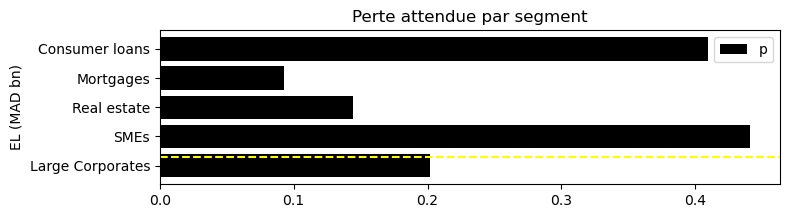

In [68]:
import matplotlib.pyplot as plt
#Les types de graphiques :
#ax.bar(x, y) : barres verticales 
#ax.barh(x, y) :barres horizontales
#ax.plot(x, y) :courbe
#ax.hist(valeurs, bins=50) :histogramme
#ax.scatter(x, y) : nuage de points
#ax.tick_params(axis="x", rotation=30)   # incliner les noms trop longs
#ax.axhline(1.5, color="red", linestyle="--")   # une ligne horizontale, par ex. une limite
#ax.plot(x, y1, marker="o", label="Série 1") : plusieurs séries sur meme graphique 
#ax.plot(x, y2, marker="o", label="Série 2")  : plusieurs séries sur meme graphique 

fig, ax = plt.subplots(figsize=(8, 2))   # 1. créer
ax.barh(df["segment"], df["EL"],color="black")          # 2. dessiner
ax.set_title("Perte attendue par segment")  # 3. habiller
ax.set_ylabel("EL (MAD bn)")
ax.legend("pertes")
ax.axhline(0.3,color="yellow",linestyle="--")
plt.show()                                 # 4. afficher

partie 4 scénario de stress 


In [69]:
DF = pd.DataFrame({
    "segment": ["Large Corporates", "SMEs", "Real estate", "Mortgages", "Consumer loans"],
    "type":    ["Entreprises", "Entreprises", "Entreprises", "Particuliers", "Particuliers"],
    "ead":     [42, 28, 9, 31, 14],
    "pd":      [0.012, 0.035, 0.04, 0.015, 0.045],
    "lgd":     [0.40, 0.45, 0.40, 0.20, 0.65]})
DF
print (DF.shape)
DF["ead"].sum()
DF["EL"]=DF["pd"]*DF["ead"]*DF["lgd"]
DF["EL_pct"]=DF["EL"]/DF["ead"]
DF

(5, 5)


,segment,type,ead,pd,lgd,EL,EL_pct
0,Large Corporates,Entreprises,42,0.012,0.40,0.2016,0.00480
1,SMEs,Entreprises,28,0.035,0.45,0.4410,0.01575
2,Real estate,Entreprises,9,0.040,0.40,0.1440,0.01600
3,Mortgages,Particuliers,31,0.015,0.20,0.0930,0.00300
4,Consumer loans,Particuliers,14,0.045,0.65,0.4095,0.02925


In [70]:
DF[(DF["pd"] > 0.03) & (DF["type"] == "Entreprises")]

,segment,type,ead,pd,lgd,EL,EL_pct
1,SMEs,Entreprises,28,0.035,0.45,0.441,0.01575
2,Real estate,Entreprises,9,0.040,0.40,0.144,0.01600


In [71]:
DF.sort_values("EL",ascending =False)

,segment,type,ead,pd,lgd,EL,EL_pct
1,SMEs,Entreprises,28,0.035,0.45,0.4410,0.01575
4,Consumer loans,Particuliers,14,0.045,0.65,0.4095,0.02925
0,Large Corporates,Entreprises,42,0.012,0.40,0.2016,0.00480
2,Real estate,Entreprises,9,0.040,0.40,0.1440,0.01600
3,Mortgages,Particuliers,31,0.015,0.20,0.0930,0.00300


In [72]:
DF["ead_part"]=DF["ead"]/DF["ead"].sum()
DF["EL_part"]=DF["EL"]/DF["EL"].sum()
DF.groupby("type")[["EL","ead","ead_part","EL_part"]].sum()


,EL,ead,ead_part,EL_part
type,,,,
Entreprises,0.7866,79,0.637097,0.610193
Particuliers,0.5025,45,0.362903,0.389807


les particuliers perdent plus que leur exposition , ils sont exposés à 36% et perdent 38% : les crédits immobiliers sont très peu risqués : la maison sert de garantie, d’où une LGD de seulement 20 %.
Les crédits à la consommation sont très risqués : pas de garantie, d’où une LGD de 65 %, et une PD élevée

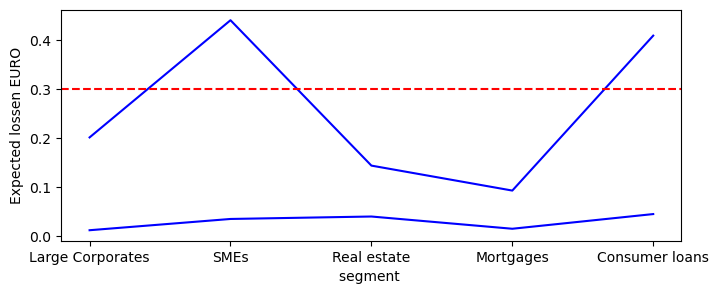

In [73]:
fig,ax=plt.subplots(figsize=(8,3))
ax.plot(DF["segment"],DF["EL"],DF["pd"], color="blue")
ax.set_ylabel("Expected lossen EURO")
ax.set_xlabel("segment ")
ax.axhline(0.3 , color="red" , linestyle="--")

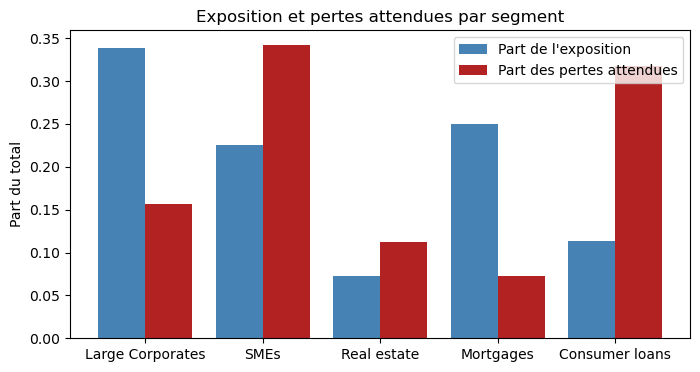

In [74]:
x = np.arange(len(DF))      # positions 0, 1, 2, 3, 4 : une par segment
largeur = 0.4
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x -largeur/2, DF["ead_part"], width=largeur, color="steelblue", label="Part de l'exposition")
ax.bar(x + largeur/2, DF["EL_part"],  width=largeur, color="firebrick", label="Part des pertes attendues")
ax.set_xticks(x, DF["segment"])
ax.set_ylabel("Part du total")
ax.set_title("Exposition et pertes attendues par segment")
ax.legend()
plt.show()

Partie 2: les stress scénarios : Un stress test répond à une question : « si l'économie se dégrade de telle façon, combien la banque perd-elle ? » On le fait pour plusieurs scénarios d'intensité croissante : • Une PD ne peut pas dépasser 100 %, ni une LGD. Avec des multiplicateurs élevés, on plafonne : np.minimum(df["pd"] * 3, 1) garde la plus petite valeur entre la PD stressée et 1. Ici, la PD la plus haute stressée vaut 13,5 %, donc le plafond ne joue pas, mais un code de stress test doit toujours le prévoir.
• Les pertes doivent croître avec la sévérité : Baseline < Adverse < Severe. Sinon, il y a un bug.

In [75]:
def EL_stressee(DF, mult_pd ,ajout_lgd) :
 pd_stresse=np.minimum(DF["pd"]*mult_pd,1)
 Lgd_stresse=np.minimum(DF["lgd"]+ajout_lgd ,1)
 return pd_stresse*Lgd_stresse*DF["ead"]
DF["EL_adverse"]=EL_stressee(DF, 2, 0.05)
DF["EL_baseline"]=EL_stressee(DF,1,0)
DF["EL_severe"]=EL_stressee(DF, 3,0.1)
DF[["segment","EL_adverse","EL_baseline","EL_severe"]]
print (DF[["EL_adverse","EL_baseline","EL_severe"]].sum())
DF[["segment","type","EL","EL_adverse","EL_baseline","EL_severe"]]


EL_adverse     2.8721
EL_baseline    1.2891
EL_severe      4.7490
dtype: float64


,segment,type,EL,EL_adverse,EL_baseline,EL_severe
0,Large Corporates,Entreprises,0.2016,0.4536,0.2016,0.7560
1,SMEs,Entreprises,0.4410,0.9800,0.4410,1.6170
2,Real estate,Entreprises,0.1440,0.3240,0.1440,0.5400
3,Mortgages,Particuliers,0.0930,0.2325,0.0930,0.4185
4,Consumer loans,Particuliers,0.4095,0.8820,0.4095,1.4175


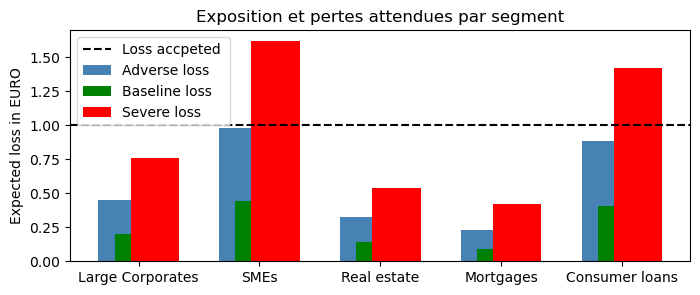

In [76]:
fig,ax=plt.subplots(figsize=(8,3))
x = np.arange(len(DF))      # positions 0, 1, 2, 3, 4 : une par segment
largeur = 0.4
ax.bar(x -largeur/3, DF["EL_adverse"], width=largeur, color="steelblue", label="Adverse loss")
ax.bar(x , DF["EL_baseline"],  width=largeur, color="green", label="Baseline loss")
ax.bar(x + largeur/3, DF["EL_severe"],  width=largeur, color="red", label="Severe loss")
ax.set_xticks(x, DF["segment"])
ax.axhline(1 , color="black" , linestyle="--",label="Loss accpeted ")
ax.set_ylabel("Expected loss in EURO")
ax.set_title("Exposition et pertes attendues par segment")
ax.legend()
plt.show()

Entre Baseline et Severe, l'EL est multipliée par 3,7 alors que les PD ne sont multipliées que par 3. D'où vient la différence ?
Réponse : L’écart vient de la LGD, stressée de +10 points en même temps que les PD. Les deux effets se multiplient : ×3 pour la PD et ×1,15 à ×1,5 pour la LGD selon le segment. L’effet est le plus fort sur les crédits immobiliers, dont la LGD faible dépend de la valeur des garanties. C’est la corrélation PD-LGD en crise : l’ignorer sous-estimerait les pertes d’environ 20 %.